# Fig. 3(d): Fabrication Robustness

This notebook loads saved results and plots focusing efficiency for optimized diffractive cascades with several element counts \(N\) against a baseline Fresnel zone plate.

The three panels show:

1. **Placement errors** — random lateral shifts in element positioning
2. **Erosion** — systematic shrinking of features
3. **Thermal expansion** — distortion of the pattern from a temperature change \(\Delta T\)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

In [2]:
import sys
from pathlib import Path

repo_root = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(repo_root))
from src.util import colors_list


In [3]:
matplotlib.rcParams['figure.dpi'] = 200
matplotlib.rcParams.update({'font.size': 24})

In [4]:
fzp_color = (np.float64(0.4), np.float64(0.6509803921568628), np.float64(0.11764705882352941), np.float64(1.0))

# Placement 

In [5]:
place_path = repo_root / "paper_data"
place_results = np.load(place_path / "fig3d_placement_robustness_results.npz", allow_pickle=True)

In [6]:
choices = place_results['choices']
fzp_mean_efficiencies = place_results['fzp_mean_efficiencies']
fzp_std_efficiencies = place_results['fzp_std_efficiencies']
opt_mean_efficiencies = place_results['opt_mean_efficiencies']
opt_std_efficiencies = place_results['opt_std_efficiencies']
placement_precision = place_results['placement_precision']
Nelem_arr = place_results['Nelem_arr']

# Erosion


In [7]:
erosion_path = repo_root / "paper_data"
erosion_results = np.load(erosion_path / "fig3d_erosion_robustness_results.npz", allow_pickle=True)

erosion_choices = erosion_results['choices']
erosion_fzp_mean_efficiencies = erosion_results['fzp_mean_efficiencies']
erosion_fzp_std_efficiencies = erosion_results['fzp_std_efficiencies']
erosion_opt_mean_efficiencies = erosion_results['opt_mean_efficiencies']
erosion_opt_std_efficiencies = erosion_results['opt_std_efficiencies']
erosion_strengths = erosion_results['morph_error_levels']
erosion_Nelem_arr = erosion_results['Nelem_arr']

# Thermal expansion

In [8]:
therm_path = repo_root / "paper_data"
therm_results = np.load(therm_path / "fig3d_thermal_robustness_results.npz", allow_pickle=True)

therm_choices = therm_results['choices']
therm_fzp_mean_efficiencies = therm_results['fzp_mean_efficiencies']
therm_fzp_std_efficiencies = therm_results['fzp_std_efficiencies']
therm_opt_mean_efficiencies = therm_results['opt_mean_efficiencies']
therm_opt_std_efficiencies = therm_results['opt_std_efficiencies']
temps = therm_results['temps']
therm_Nelem_arr = therm_results['Nelem_arr']

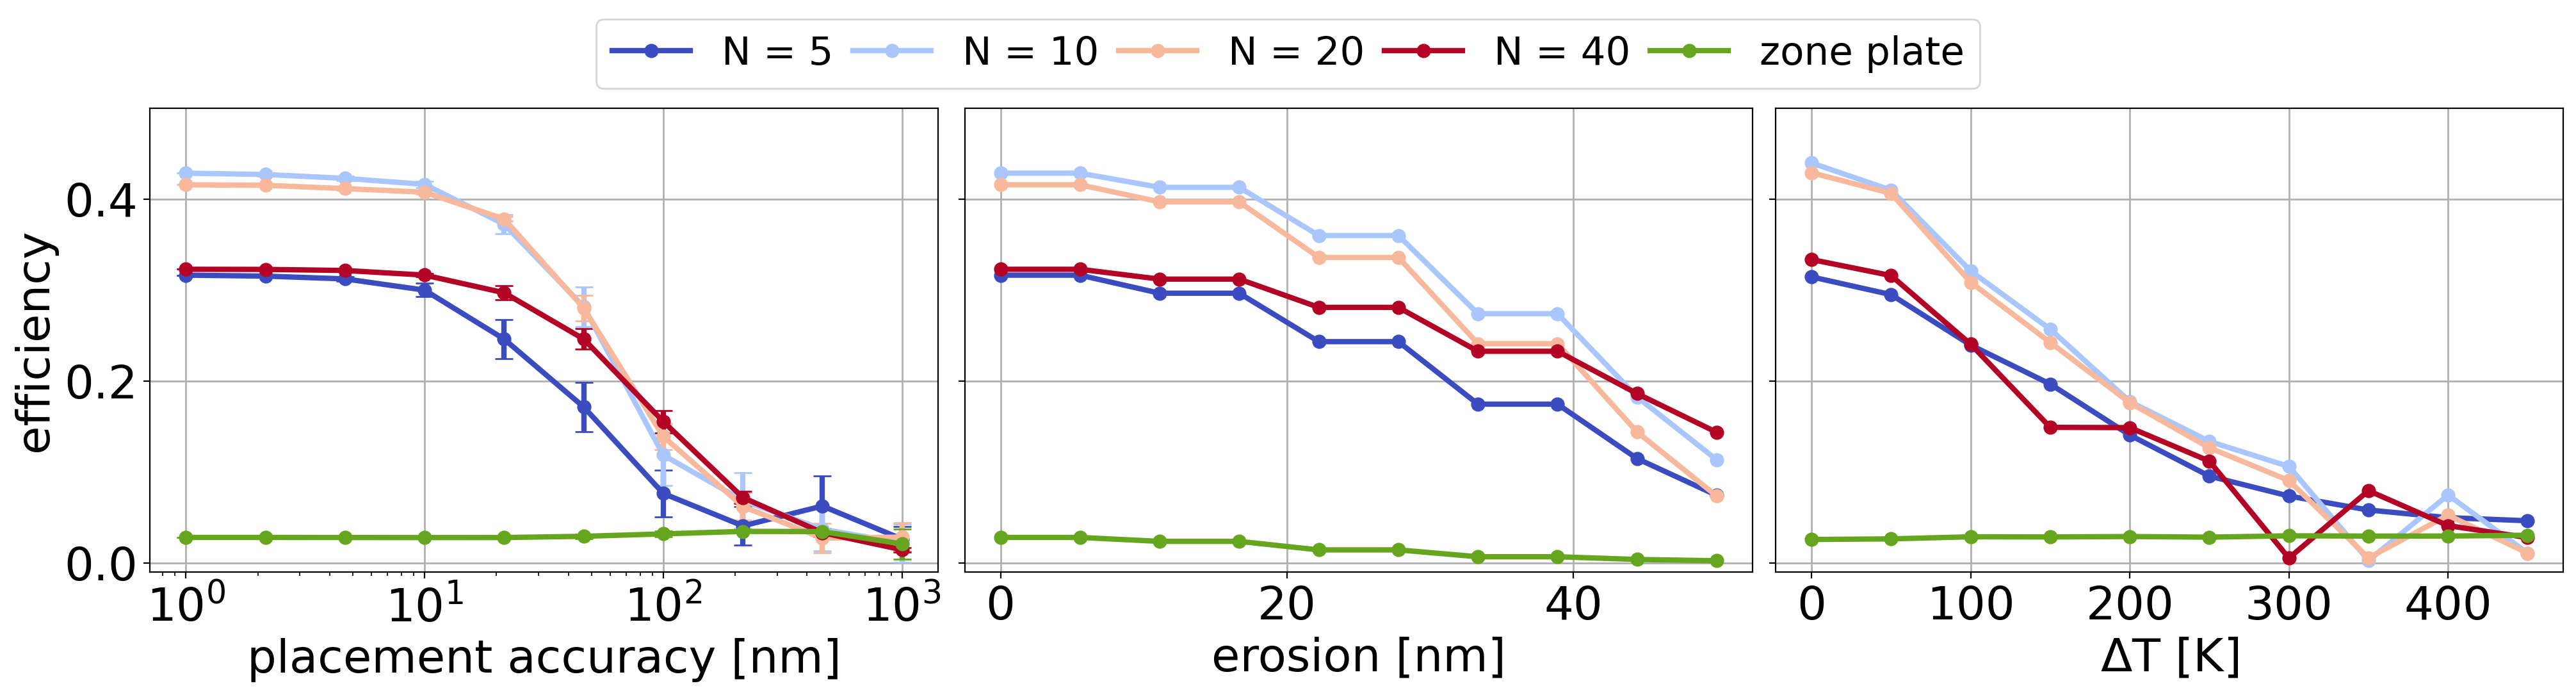

In [9]:
colors = colors_list(len(therm_Nelem_arr))

fig, ax = plt.subplots(1, 3, figsize=(20, 5.5), sharey=True, layout="constrained")
fig.get_layout_engine().set(h_pad=0.12)

ax[0].set_xscale('log')
ax[0].set_xlabel("placement accuracy [nm]", fontsize=26)

for i in range(len(Nelem_arr)):
    ax[0].errorbar(placement_precision, opt_mean_efficiencies[i], 
                yerr=opt_std_efficiencies[i], 
                linewidth=3, fmt='-o', capsize=5, markersize=7, 
                label=f'N = {Nelem_arr[i]}', color=colors[i])
    
ax[0].errorbar(placement_precision, fzp_mean_efficiencies[0], 
            yerr=fzp_std_efficiencies[0], 
            linewidth=3, fmt='-o', capsize=5, markersize=7, 
            label='zone plate', color=fzp_color)

ax[1].set_xlabel("erosion [nm]", fontsize=26)

for i in range(len(erosion_Nelem_arr)):
    ax[1].plot(erosion_strengths*1e9, erosion_opt_mean_efficiencies[i], linewidth=3, marker='o', markersize=7, label=f'N = {erosion_Nelem_arr[i]}', color=colors[i])
    
ax[1].plot(erosion_strengths*1e9, erosion_fzp_mean_efficiencies[0], linewidth=3, marker='o', markersize=7, label='zone plate', color=fzp_color)

ax[2].set_xlabel("$\\Delta$T [K]", fontsize=26)

for i in range(len(therm_Nelem_arr)):
    ax[2].plot(temps, therm_opt_mean_efficiencies[i], linewidth=3, marker='o', markersize=7, label=f'N = {therm_Nelem_arr[i]}', color=colors[i])
    
ax[2].plot(temps, therm_fzp_mean_efficiencies[0], linewidth=3, marker='o', markersize=7, label='zone plate', color=fzp_color)

for idx, axi in enumerate(ax):
    # Formatting each subplot
    axi.set_ylim(-0.01, 0.5)
    axi.tick_params(labelsize=26)
    axi.grid(True, linewidth=1)
    
    # Only show legend on the first or last plot to avoid clutter, 
    # or adjust as needed.
    if idx == 0:
        axi.set_ylabel("efficiency", fontsize=26)

handles, labels = ax[1].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside upper center', ncol=5, columnspacing=0.5, fontsize=22)

plt.show()